In [ ]:
!gdown 1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6


Downloading...
From: https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6
To: /content/customer_train.csv
100% 425k/425k [00:00<00:00, 72.3MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('customer_train.csv')
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
df['Segmentation'].value_counts()

,count
Segmentation,
D,2268
A,1972
C,1970
B,1858


In [ ]:
df.drop(columns=['Var_1', 'ID'], inplace=True)

df.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,A


In [ ]:
df.isnull().sum()

,0
Gender,0
Ever_Married,140
Age,0
Graduated,78
Profession,124
Work_Experience,829
Spending_Score,0
Family_Size,335
Segmentation,0


In [ ]:
df.shape

(8068, 9)

In [ ]:
df['Work_Experience']= df['Work_Experience'].fillna(0.0)

In [ ]:
df['Family_Size']= df['Family_Size'].fillna(df['Family_Size'].median())

In [ ]:
df.isnull().sum()

,0
Gender,0
Ever_Married,140
Age,0
Graduated,78
Profession,124
Work_Experience,0
Spending_Score,0
Family_Size,0
Segmentation,0


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,0
Spending_Score,0
Family_Size,0
Segmentation,0


In [ ]:
df.shape

(7741, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7741 entries, 0 to 8067
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Gender           7741 non-null   object 
 1   Ever_Married     7741 non-null   object 
 2   Age              7741 non-null   int64  
 3   Graduated        7741 non-null   object 
 4   Profession       7741 non-null   object 
 5   Work_Experience  7741 non-null   float64
 6   Spending_Score   7741 non-null   object 
 7   Family_Size      7741 non-null   float64
 8   Segmentation     7741 non-null   object 
dtypes: float64(2), int64(1), object(6)
memory usage: 604.8+ KB


### Feature Encoding
Let's check the unique values of our categorical columns to decide on the best encoding strategy (e.g., Ordinal/Label encoding for ordered/binary categories, and One-Hot encoding for nominal ones).

In [ ]:
# Print unique values for categorical features to understand their structure
for col in ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Segmentation']:
    print(f"{col}: {df[col].unique()}")

We will use:
- **Label/Ordinal Encoding** for binary categories (`Gender`, `Ever_Married`, `Graduated`) and ordinal categories (`Spending_Score` has Low, Average, High).
- **One-Hot Encoding** (or pandas `get_dummies`) for `Profession` since it contains multiple non-ordinal categories.
- **Label Encoding** for the target variable `Segmentation`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Copy dataframe to preserve original data
df_encoded = df.copy()

# 1. Binary / Simple categorical encoding
le = LabelEncoder()
for col in ['Gender', 'Ever_Married', 'Graduated']:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# 2. Ordinal mapping for Spending_Score
spending_map = {'Low': 0, 'Average': 1, 'High': 2}
df_encoded['Spending_Score'] = df_encoded['Spending_Score'].map(spending_map)

# 3. Label encode the target variable
df_encoded['Segmentation'] = le.fit_transform(df_encoded['Segmentation'])

# 4. One-Hot encoding for Profession
df_encoded = pd.get_dummies(df_encoded, columns=['Profession'], dtype=int)

display(df_encoded.head())

,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size,Segmentation,Profession_Artist,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,1,0,22,0,1.0,0,4.0,3,0,0,0,0,0,1,0,0,0
1,0,1,38,1,0.0,1,3.0,0,0,0,1,0,0,0,0,0,0
2,0,1,67,1,1.0,0,1.0,1,0,0,1,0,0,0,0,0,0
3,1,1,67,1,0.0,2,2.0,1,0,0,0,0,0,0,0,1,0
4,0,1,40,1,0.0,2,6.0,0,0,0,0,1,0,0,0,0,0


### Train-Validation-Test Split
Let's prepare the feature matrix `X` and target vector `y`, and then perform the two stages of splitting as specified.

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df_encoded.drop(columns=['Segmentation'])
y = df_encoded['Segmentation']

# First split: Separate out 10% for the test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

# Second split: Split the remaining 90% into train and validation sets (10% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1, random_state=42, stratify=y_train_val
)

# Print the shapes of the resulting datasets
print(f"Original dataset shape: {X.shape}")
print(f"Train set shape:        {X_train.shape} (y_train: {y_train.shape})")
print(f"Validation set shape:   {X_val.shape} (y_val: {y_val.shape})")
print(f"Test set shape:         {X_test.shape} (y_test: {y_test.shape})")

Original dataset shape: (7741, 16)
Train set shape:        (6269, 16) (y_train: (6269,))
Validation set shape:   (697, 16) (y_val: (697,))
Test set shape:         (775, 16) (y_test: (775,))


### Feature Scaling (Standardization)
We will create `X_val_df` as a backup copy of our unscaled validation features, and then apply `StandardScaler` to standardize our feature sets (`X_train`, `X_val`, `X_test`).

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create a backup copy of the unscaled validation features
X_val_df = X_val.copy()

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on training data and transform all splits
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.long)
y_val_t   = torch.tensor(y_val.values,   dtype=torch.long)
y_test_t  = torch.tensor(y_test.values,  dtype=torch.long)



In [ ]:
def create_baseline(in_features, n_classes=4):
    model = nn.Sequential(
        nn.Linear(in_features, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, n_classes),          # raw logits: no softmax here, nn.CrossEntropyLoss adds it
    )
    # Glorot (Xavier) initialization with zero biases
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

In [ ]:
model = create_baseline(X_train_t.shape[1])
print(model)

Sequential(
  (0): Linear(in_features=16, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=8, bias=True)
  (7): ReLU()
  (8): Linear(in_features=8, out_features=4, bias=True)
)


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

loss_fn = nn.CrossEntropyLoss()

def predict(model, X):
    # Returns the raw scores and the predicted class, with gradient tracking switched off
    model.eval()
    with torch.no_grad():
        logits = model(X)
    return logits, logits.argmax(dim=1)

def train_model(model, lr=1e-3, epochs=10, batch_size=128):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {k: [] for k in ["loss", "precision", "recall", "f1",
                               "val_loss", "val_precision", "val_recall", "val_f1"]}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()              # 1. clear the old gradients
            loss = loss_fn(model(xb), yb)      # 2. forward pass and loss
            loss.backward()                    # 3. backpropagation
            optimizer.step()                   # 4. update the weights

        # metrics on the full train and validation sets at the end of every epoch
        for prefix, X_, y_ in [("", X_train_t, y_train_t), ("val_", X_val_t, y_val_t)]:
            logits, pred = predict(model, X_)
            y_np, p_np = y_.numpy(), pred.numpy()
            history[prefix + "loss"].append(loss_fn(logits, y_).item())
            history[prefix + "precision"].append(precision_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "recall"].append(recall_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "f1"].append(f1_score(y_np, p_np, average="macro", zero_division=0))
    return history

In [ ]:
def plot_history(history, metric, title=None):
    epochs = range(1, len(history[metric]) + 1)
    plt.plot(epochs, history[metric], label="train")
    plt.plot(epochs, history["val_" + metric], label="validation")
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.title(title or f"{metric} vs epochs")
    plt.show()

In [ ]:
torch.manual_seed(42)
model = create_baseline(X_train_t.shape[1])

history = train_model(model, lr=1e-3, epochs=10, batch_size=128)

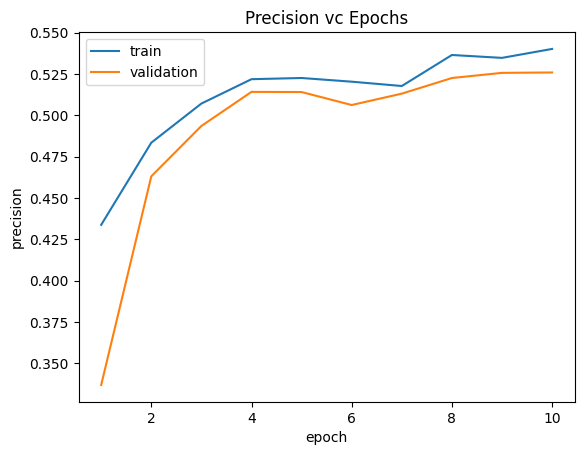

In [ ]:
plot_history(history, "precision", "Precision vc Epochs")

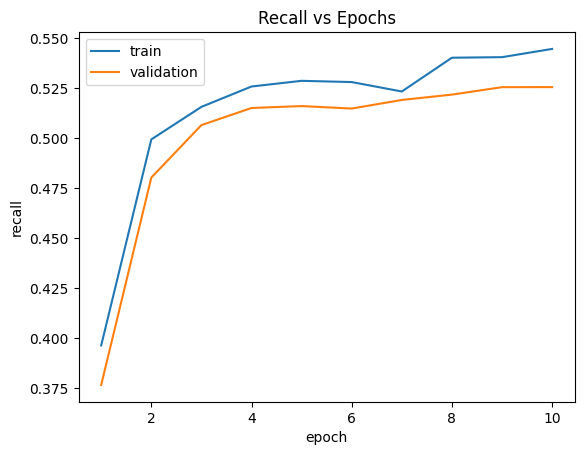

In [ ]:
plot_history(history, "recall", "Recall vs Epochs")

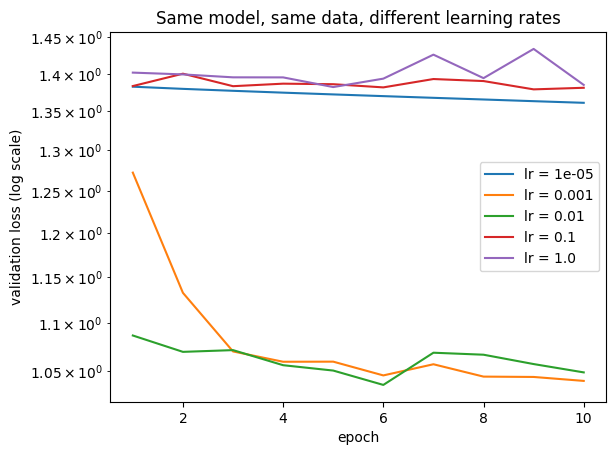

,final validation loss
0.00001,1.3609
0.00100,1.0404
0.01000,1.0490
0.10000,1.3808
1.00000,1.3847


In [ ]:
lr_results = {}
for lr in [1e-5, 1e-3, 1e-2, 1e-1, 1.0]:
    torch.manual_seed(42)                                   # same starting weights for every run
    lr_results[lr] = train_model(create_baseline(X_train_t.shape[1]), lr=lr, epochs=10)

for lr, h in lr_results.items():
    plt.plot(range(1, 11), h["val_loss"], label=f"lr = {lr}")
plt.xlabel("epoch")
plt.ylabel("validation loss (log scale)")
plt.yscale("log")                                           # a log scale keeps a diverging run from hiding the others
plt.legend()
plt.title("Same model, same data, different learning rates")
plt.show()

pd.Series({lr: round(h["val_loss"][-1], 4) for lr, h in lr_results.items()}, name="final validation loss")

In [ ]:
rng = np.random.default_rng(0)
trials = []
for t in range(5):
    lr = 10 ** rng.uniform(-4, -1)                         # log-uniform sample between 1e-4 and 1e-1
    bs = int(rng.choice([32, 64, 128, 256]))
    torch.manual_seed(42)
    h = train_model(create_baseline(X_train_t.shape[1]), lr=lr, epochs=10, batch_size=bs)
    trials.append((round(lr, 5), bs, round(h["val_loss"][-1], 4), round(h["val_f1"][-1], 4)))

pd.DataFrame(trials, columns=["lr", "batch_size", "val_loss", "val_f1"]).sort_values("val_loss")

,lr,batch_size,val_loss,val_f1
4,0.00661,256,1.0417,0.5381
0,0.00814,128,1.0582,0.5012
2,0.00011,32,1.0794,0.4879
3,0.05474,256,1.0832,0.5157
1,0.00013,64,1.1019,0.4635


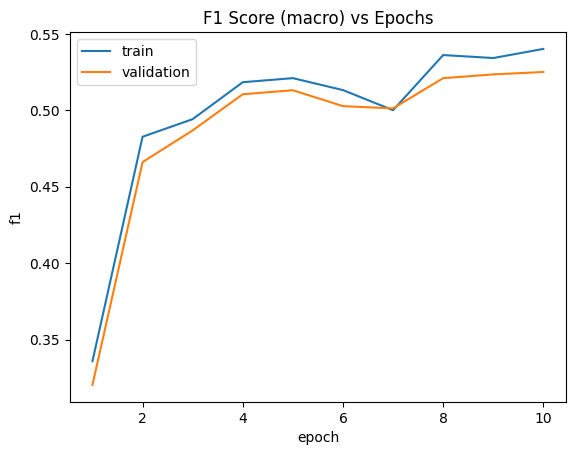

In [ ]:
plot_history(history, "f1", "F1 Score (macro) vs Epochs")


In [ ]:
from sklearn.metrics import accuracy_score

_, val_pred = predict(model, X_val_t)
val_pred = val_pred.numpy()

print("accuracy        :", round(accuracy_score(y_val, val_pred), 4))
print("micro precision :", round(precision_score(y_val, val_pred, average="micro"), 4))
print("micro recall    :", round(recall_score(y_val, val_pred, average="micro"), 4))
print("micro F1        :", round(f1_score(y_val, val_pred, average="micro"), 4))
print("macro F1        :", round(f1_score(y_val, val_pred, average="macro"), 4))

accuracy        : 0.5423
micro precision : 0.5423
micro recall    : 0.5423
micro F1        : 0.5423
macro F1        : 0.525


In [ ]:
# 95% of the samples belong to class 0, and the model always predicts class 0
y_true = np.array([0] * 95 + [1] * 5)
y_pred = np.zeros(100, dtype=int)

print("accuracy :", accuracy_score(y_true, y_pred))
print("micro F1 :", round(f1_score(y_true, y_pred, average="micro"), 3))
print("macro F1 :", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 3))

accuracy : 0.95
micro F1 : 0.95
macro F1 : 0.487


In [ ]:
_, test_pred = predict(model, X_test_t)
test_pred = test_pred.numpy()

print("Test macro F1      :", round(f1_score(y_test, test_pred, average="macro"), 4))
print("Validation macro F1:", round(f1_score(y_val, val_pred, average="macro"), 4))

Test macro F1      : 0.5074
Validation macro F1: 0.525
